# Centric case study: from an HR director's request to a Power BI model

**Workforce analytics for a fictional 600-person IT services company (Kaunas and Vilnius, Nov 2024 - Oct 2026).**

All HR, timesheet, recruiting and finance data in this notebook are **SIMULATED** (`src/simulate_company.py`, seed 42). They are not Centric data.
Public data (**PUBLIC DATA**: Eurostat, Statistics Lithuania, Nager.Date) only calibrate the simulation and feed the `Market` table.

The starting request was: *"I need a monthly turnover report by department."* This notebook follows the analysis behind the answer:
data quality → headcount and FTE → attrition under three definitions → overload then exits → pay compression vs market →
Vilnius hiring cohorts → utilisation, bench and the cut-off rule → HR vs finance reconciliation → conclusions.
Every query lives in `sql/` (DuckDB); this notebook runs them and reads the results.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import pandas as pd
from run_sql import main as run_sql
import charts
%matplotlib inline
import matplotlib.pyplot as plt
from IPython.display import display

con = run_sql()                     # loads data/sim + data/public into DuckDB, runs sql/01..06 + kpi_checks.sql
q = lambda sql: con.execute(sql).df()
def show(f):
    fig = f(); display(fig); plt.close(fig)
pd.set_option("display.width", 160)

7 SQL files, 25 outputs -> data/output/


## 1. Data quality first (`sql/01_data_quality.sql`)
Before any KPI: duplicate ids, overlapping SCD2 periods, missing fields, late timesheets.

In [2]:
q('SELECT * FROM out_dq_summary')

,check_name,issues,fix
0,"Duplicate employee ids (same person, two ids)",18,Flag is_duplicate_id; count the master id only
1,Overlapping SCD2 periods,5,Cut the older row the day before the next row ...
2,Rows with missing manager_id,9,"Report as ""Unassigned""; ask HR to complete"
3,Rows with missing site,4,Take the site from the cost centre
4,Timesheets entered > 10 days after month end,252,Cut-off rule: report closed months only
5,Months not closed at extract date,1,"Show as provisional, excluded from KPIs"


In [3]:
# The 18 duplicate ids all appear on the day of the HRIS migration and never log time: they are ghosts, not people.
q('SELECT first_seen, count(*) AS duplicate_ids, sum(timesheet_rows) AS timesheet_rows FROM out_dq_duplicates GROUP BY 1')

,first_seen,duplicate_ids,timesheet_rows
0,2025-09-01,18,0.0


## 2. Headcount and FTE from the SCD2 history (`sql/02_headcount_fte.sql`)

In [4]:
h = q('SELECT * FROM out_headcount_company')
h[h.month_start.astype(str).between('2025-07-01', '2025-11-01')]

,month_start,headcount_raw,headcount,fte,duplicate_ids,avg_headcount_r12m
8,2025-07-01,606.0,606.0,593.5,0.0,586.3
9,2025-08-01,600.0,600.0,587.5,0.0,587.7
10,2025-09-01,613.0,595.0,583.2,18.0,588.4
11,2025-10-01,616.0,598.0,586.2,18.0,589.2
12,2025-11-01,623.0,605.0,592.5,18.0,591.7


Raw HRIS headcount jumps by 18 (+3%) in September 2025 with no matching hires: that is the migration, not growth. From here on, KPIs count master ids only.

## 3. Turnover under three definitions (`sql/03_attrition.sql`)
The request said *turnover*. The data show why the definition must be agreed first.

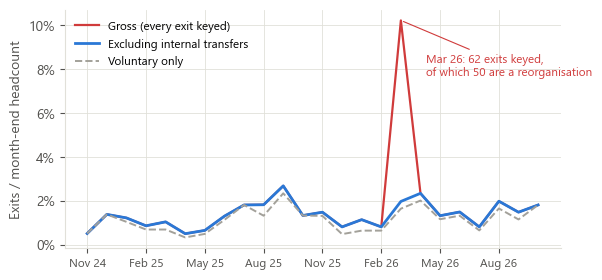

In [5]:
show(charts.three_definitions)

In [6]:
q('SELECT * FROM out_attrition_false_signal')

,department,month_start,headcount,exits_gross,exits_excl_transfers,exits_voluntary,rate_gross,rate_excl_transfers
0,Delivery 2,2026-01-01,121.0,2,2,1,0.017,0.017
1,Delivery 2,2026-02-01,121.0,0,0,0,0.000,0.000
2,Delivery 2,2026-03-01,123.0,50,0,0,0.407,0.000
3,Delivery 2,2026-04-01,119.0,4,4,4,0.034,0.034
4,Delivery 2,2026-05-01,116.0,3,3,2,0.026,0.026


In [7]:
d = q('SELECT * FROM out_attrition_definitions')
d[['month_start', 'rate_gross_r12m', 'rate_excl_transfers_r12m', 'rate_voluntary_r12m', 'rate_regretted_r12m']].tail(3)

,month_start,rate_gross_r12m,rate_excl_transfers_r12m,rate_voluntary_r12m,rate_regretted_r12m
21,2026-08-01,0.2650,0.1822,0.1524,0.0696
22,2026-09-01,0.2532,0.1704,0.1407,0.0678
23,2026-10-01,0.2579,0.1753,0.1455,0.0744


**False signal, not raised.** In March 2026, Delivery 2 shows 50 gross exits, but all 50 people were rehired the next day under the same id:
a reorganisation keyed as exit + hire. Excluding internal transfers, Delivery 2 had **0** exits that month. Gross turnover would have
put a crisis in front of the board that does not exist. The agreed headline KPI is **regretted voluntary attrition, rolling 12 months, excluding internal transfers**.

## 4. Data & Cloud: overload first, regretted exits next

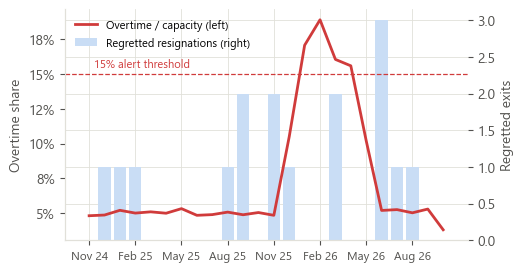

In [8]:
show(charts.dc_overload)

In [9]:
a = q("SELECT * FROM out_attrition_monthly WHERE department = 'Data & Cloud'")
cuts = [pd.Timestamp('2024-10-31'), pd.Timestamp('2026-02-28'), pd.Timestamp('2026-08-31'), pd.Timestamp('2026-12-31')]
a['period'] = pd.cut(pd.to_datetime(a.month_start), cuts, labels=['Nov 24 - Feb 26 (before)', 'Mar 26 - Aug 26 (after overload)', 'Sep 26 - Oct 26'])
a.groupby('period', observed=True).agg(months=('month_start', 'count'), regretted=('exits_regretted', 'sum')).assign(per_month=lambda x: (x.regretted / x.months).round(2))

,months,regretted,per_month
period,,,
Nov 24 - Feb 26 (before),16,9,0.56
Mar 26 - Aug 26 (after overload),6,7,1.17
Sep 26 - Oct 26,2,0,0.00


In [10]:
q("SELECT exit_reason, sum(exits) AS exits FROM out_exit_reasons WHERE department = 'Data & Cloud' AND quarter_start >= DATE '2026-01-01' GROUP BY 1 ORDER BY 2 DESC")

,exit_reason,exits
0,Workload / burnout,5.0
1,Role not as expected,3.0
2,Career growth,2.0
3,Better pay elsewhere,1.0


Overtime stayed above 15% of capacity for four months (Jan-Apr 2026); regretted resignations then doubled, with *workload / burnout* as the leading reason. Overtime is a leading indicator: it gets an alert threshold in the model.

## 5. Pay compression against the market (`sql/05_compensation_market.sql`)

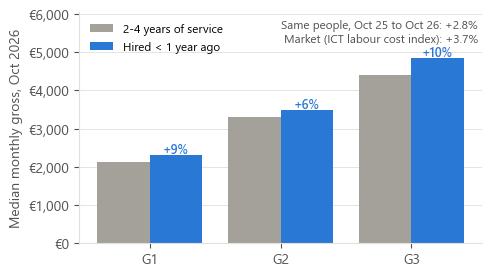

In [11]:
show(charts.pay_compression)

In [12]:
q('SELECT * FROM out_pay_like_for_like')

,people,median_raise,market_growth_4q
0,469,0.0283,0.0374


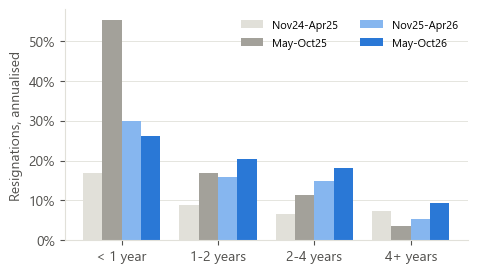

In [13]:
show(charts.tenure_exits)

In [14]:
q("SELECT * FROM out_exits_by_tenure WHERE tenure_band = '2-4 y'")

,half,tenure_band,avg_headcount,voluntary_exits,pay_reason_exits,annualised_rate
0,H0 Nov24-Apr25,2-4 y,149.5,5,3,0.067
1,H1 May-Oct25,2-4 y,159.5,9,5,0.113
2,H2 Nov25-Apr26,2-4 y,147.2,11,8,0.149
3,H3 May-Oct26,2-4 y,154.7,14,8,0.181


In [15]:
q('SELECT quarter, company_avg_gross, osp_ict_avg_gross, company_vs_osp_ict FROM out_pay_vs_market WHERE company_avg_gross IS NOT NULL')

,quarter,company_avg_gross,osp_ict_avg_gross,company_vs_osp_ict
0,2024-Q4,3108.0,4026.6,0.772
1,2025-Q1,3324.0,4135.4,0.804
2,2025-Q2,3298.0,4166.3,0.792
3,2025-Q3,3321.0,4055.5,0.819
4,2025-Q4,3308.0,4190.6,0.789
5,2026-Q1,3458.0,NaN,NaN
6,2026-Q2,3454.0,NaN,NaN


Same people, same grade: +2.8% in a year while the ICT labour cost index (PUBLIC DATA) rose about 3.7%; new hires earn 6-10% more than
colleagues with 2-4 years of service in the same grade. Resignations in that tenure band rose from about 7% to 18% (annualised), mostly for
*better pay elsewhere*. The company also pays below the Lithuanian ICT average (about 79% of it), but that average mixes very different jobs:
it is context, not a target.

## 6. The Vilnius 2025 hiring wave

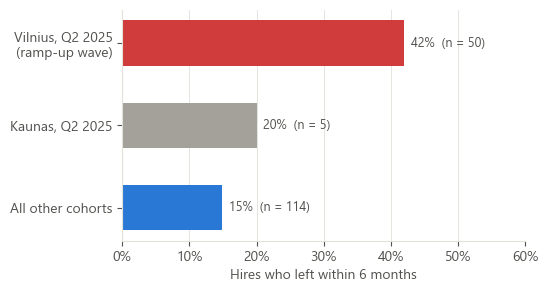

In [16]:
show(charts.cohorts)

In [17]:
q("SELECT * FROM out_cohort_retention WHERE hire_quarter IN ('2025-Q1', '2025-Q2', '2025-Q3') ORDER BY hire_quarter, site")

,hire_quarter,site,hires,left_within_6m,share_left_6m,share_left_12m,six_months_observed
0,2025-Q1,Kaunas,13,1,0.077,0.077,True
1,2025-Q1,Vilnius,3,1,0.333,0.333,True
2,2025-Q2,Kaunas,5,1,0.200,0.400,True
3,2025-Q2,Vilnius,50,21,0.420,0.480,True
4,2025-Q3,Kaunas,9,0,0.000,0.333,True
5,2025-Q3,Vilnius,11,1,0.091,0.091,True


42% of the Q2 2025 Vilnius ramp-up hires left within six months, against 15% for all other cohorts. Exit reasons point to onboarding and role fit, not pay.

## 7. Utilisation, bench and the month that always looks bad (`sql/04_utilization.sql`)

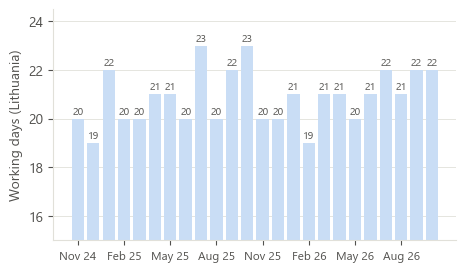

In [18]:
show(charts.working_days)

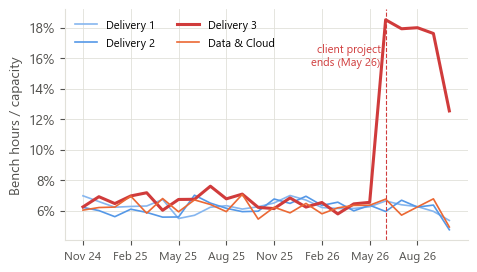

In [19]:
show(charts.bench)

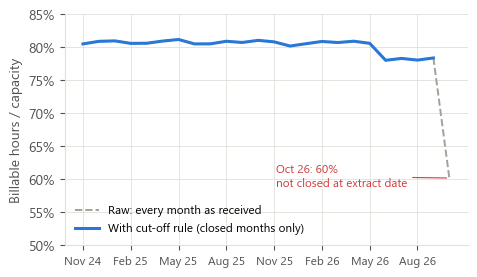

In [20]:
show(charts.cutoff)

In [21]:
q('SELECT * FROM out_utilization_delivery').tail(4)

,month_start,is_closed,working_days,utilization_all_months,utilization_closed_only,bench_share,logged_share
20,2026-07-01,True,22,0.7831,0.7831,0.0881,0.8712
21,2026-08-01,True,21,0.7806,0.7806,0.0880,0.8686
22,2026-09-01,True,22,0.7838,0.7838,0.0878,0.8715
23,2026-10-01,False,22,0.6019,NaN,0.0667,0.6686


Two different stories. **Delivery 3** lost a large client project at the end of May 2026: bench went from about 7% to 18% of capacity and
utilisation from 80% to 69%. That is real and needs a staffing plan. **October 2026** looks 18 points worse than September only because
timesheets arrive up to 10 days after month end and the extract was taken on 6 November: the cut-off rule shows a month only once it is closed.

## 8. Can we trust the numbers? HR vs finance (`sql/06_hr_finance_reconciliation.sql`)

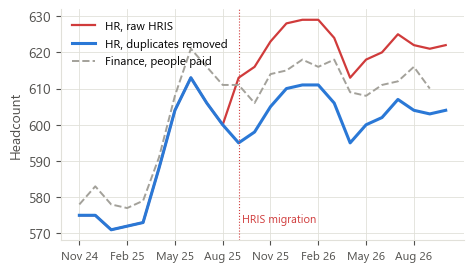

In [22]:
show(charts.hr_vs_finance)

In [23]:
q('SELECT * FROM out_recon_bridge').tail(3)

,month_start,hr_raw_month_end,less_duplicate_ids,plus_leavers_in_month,finance_headcount,residual
20,2026-07-01,625,-18,5,612.0,0.0
21,2026-08-01,622,-18,12,616.0,0.0
22,2026-09-01,621,-18,7,610.0,0.0


In [24]:
q('SELECT * FROM out_recon_cost_center')

,month_start,cost_center,department_master,department_reported,payroll_headcount,revenue_eur
0,2026-05-01,CC-D1-VNO,Delivery 1,Data & Cloud,89,524569.0
1,2026-06-01,CC-D1-VNO,Delivery 1,Data & Cloud,91,555022.0
2,2026-07-01,CC-D1-VNO,Delivery 1,Data & Cloud,91,509353.0


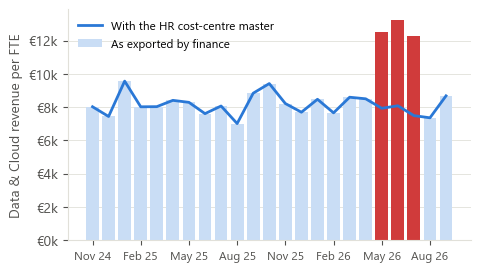

In [25]:
show(charts.revenue_per_fte)

The bridge closes to zero every month: HR raw - 18 duplicate ids + leavers paid in their last month = finance headcount. By department, the finance export put cost centre CC-D1-VNO under Data & Cloud from May to July 2026, which made Data & Cloud revenue per FTE jump by about 60% (+62% on average over the three months). Fix: map cost centres with the HR master, and run the reconciliation every month before publishing.

## 9. Every KPI checked twice (`sql/kpi_checks.sql` vs model tables, see `docs/KPI_CHECKS.md`)

In [26]:
q('SELECT * FROM out_kpi_checks')

,kpi,context,sql_value
0,Headcount,"Sep 2026, company",603.0000
1,Headcount (raw HRIS),"Sep 2026, company",621.0000
2,FTE,"Sep 2026, company",591.4000
3,Average Headcount,R12M to Sep 2026,604.3000
4,Exits (gross),R12M to Sep 2026,153.0000
5,Attrition % (gross),R12M to Sep 2026,0.2532
6,Attrition % (excl. transfers),R12M to Sep 2026,0.1704
7,Voluntary Attrition %,R12M to Sep 2026,0.1407
8,Regretted Attrition %,R12M to Sep 2026,0.0678
9,Voluntary Attrition %,"R12M to Sep 2026, Data & Cloud",0.1446


## 10. Conclusions and recommendations

1. **Change the request, not just the report.** Replace *monthly turnover by department* with **regretted voluntary attrition, rolling 12 months, excluding internal transfers**, shown next to headcount and the gross figure for reference.
2. **Do not escalate March 2026.** The Delivery 2 spike is a keying convention (exit + rehire). Ask HR to key reorganisations as transfers.
3. **Act on Data & Cloud workload.** Alert when overtime exceeds 15% of capacity two months in a row; regretted exits follow about two months later.
4. **Review pay for 2-4 year staff.** Like-for-like raises trail the market and new hires out-earn them; resignations at that tenure more than doubled.
5. **Fix onboarding before the next ramp-up.** The Vilnius 2025 wave lost 42% of hires within six months.
6. **Plan Delivery 3 capacity.** Bench at 18% since June 2026: redeploy, re-skill or slow hiring.
7. **Make trust visible.** Publish only closed months; remove the 18 duplicate ids; reconcile HR and finance headcount monthly; map cost centres from one master.